# Machine Learning – Assignment 3 · Notebook 1: Batch Gradient Descent + Random Forest

**Project:** *Student Academic Performance Prediction Using Random Forest: A Comparative Study of Five Optimization Algorithms for Feature Selection*

**Student:** _[Student Name]_ · **ID:** _[Student ID]_ · **University:** _[University Name]_ · **Course:** Machine Learning

This notebook trains the differentiable feature-selection surrogate with **Batch Gradient Descent** and passes the selected attributes to a Random Forest. It also contains the full exploratory data analysis of the dataset.

---
### How this notebook fits into the project

| Notebook | Optimizer used for differentiable feature selection |
|---|---|
| `01_GD_Random_Forest.ipynb` | Batch Gradient Descent |
| `02_SGD_Random_Forest.ipynb` | Stochastic Gradient Descent |
| `03_MiniBatch_Random_Forest.ipynb` | Mini-Batch Gradient Descent |
| `04_RMSProp_Random_Forest.ipynb` | RMSProp |
| `05_Adam_Random_Forest.ipynb` | Adam **+ final comparison of all five** |

Every notebook is **self-contained** (no shared variables or files are needed besides `student-mat.csv`) and uses the **same** data split, surrogate model, initial weights, epoch budget, feature budget, Random Forest configuration and evaluation protocol. **Only the optimizer and its own learning rate change.**

## 1. Scientific design: what the optimizer actually optimizes

**Random Forest is not trained by gradient descent.** Each tree is grown greedily by choosing impurity-reducing splits on bootstrap samples (bagging), and the forest predicts by **majority vote**. A gradient-based optimizer therefore cannot "optimize Random Forest" directly.

Instead, the optimizer trains a **differentiable feature-selection model** (a *surrogate*), and its learned feature scores decide which attributes the Random Forest receives:

```
Input attributes ─► Differentiable feature gates ─► Multinomial logistic surrogate   (trained by the optimizer)
                         │
                         └─ gate values = feature-selection scores ─► top-K attributes ─► Random Forest ─► Prediction
```

**Surrogate model.** For a student with standardized encoded features $x\in\mathbb{R}^{d}$, every *original* attribute $a$ gets one non-negative gate $g_a=\operatorname{softplus}(\gamma_a)$ (all one-hot columns of an attribute share the same gate). With $\pi(j)$ the attribute of column $j$:

$$z_j = g_{\pi(j)}\,x_j,\qquad \hat p = \operatorname{softmax}(W^\top z + b)\in\mathbb{R}^3$$

**Loss function** (minimized by every optimizer):

$$\mathcal{L}(\gamma,W,b)=\underbrace{-\frac1{|B|}\sum_{i\in B}\log \hat p_{i,y_i}}_{\text{cross-entropy}}\;+\;\lambda_g\,\frac1A\sum_{a=1}^{A} g_a\;+\;\lambda_w\,\lVert W\rVert_F^2$$

The gate penalty pushes uninformative gates towards 0, while the weight decay stops the model from cheating by shrinking a gate and inflating its weights. After training, **the gate values $g_a$ are the feature-selection scores**; the top-$K$ attributes are passed to Random Forest. These scores are *not* Random Forest's own feature importance (MDI), which is reported separately.

**Fairness rules (identical in all notebooks):** same split · same initial weights (seed 42) · same shuffling sequence · same epoch budget (150 passes over the data) · same surrogate regularization · same feature budget $K$ · same Random Forest (`n_estimators=100, random_state=42, n_jobs=-1`). The only optimizer-specific setting is the **learning rate**, chosen from the optimizer's own grid by cross-validation on the training set.

**Leakage control.** The test set (20 %) is split off first and used **once**, for the final evaluation. Encoding/scaling, regularization calibration, feature-budget choice, learning-rate tuning and feature selection are all fitted on training rows only (inside CV folds where applicable).

### Prediction timing (important limitation)

* **Primary scenario – early warning (used for all optimizer experiments):** predictions use only demographic, social and school-related attributes collected by questionnaire. **G1 and G2 are excluded**, so the model can flag at-risk students *before any period grade exists*. Note that `absences` accumulates during the year; in deployment it would be "absences so far", so this is an *early-in-the-year* rather than a strictly *pre-year* prediction.
* **G3 is always removed** from the inputs after `Performance_Level` is created (direct target leakage).
* **Mid-year scenario (sensitivity analysis in Notebook 5 only):** G1 and G2 are added, assuming the first two period grades are already known. Results from that scenario must **not** be presented as predicting performance before the school year begins.

In [1]:
# ---------------------------------------------------------------
# Imports, reproducibility settings and output folder
# ---------------------------------------------------------------
import os, io, glob, time, json, hashlib, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import torch
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)
try:
    from IPython.display import display
except ImportError:          # running as a plain script
    display = print

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)                 # tiny tensors: one thread is faster and bit-for-bit reproducible
torch.set_default_dtype(torch.float64)   # double precision for exact optimizer verification
torch.use_deterministic_algorithms(True)

RESULTS_DIR = "results"                  # relative path -> works in Jupyter, Colab and Kaggle
os.makedirs(RESULTS_DIR, exist_ok=True)

print(f"Python libs | numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} "
      f"| torch {torch.__version__} | matplotlib {matplotlib.__version__}")

Python libs | numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1 | torch 2.15.0+cu132 | matplotlib 3.11.2


In [2]:
# ---------------------------------------------------------------
# Chart style: one consistent, colour-blind-checked palette for all notebooks
# ---------------------------------------------------------------
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8985", "axes.labelcolor": "#2b2b2a", "axes.titleweight": "bold",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False,
})
INK, MUTED, NEUTRAL = "#2b2b2a", "#8a8985", "#b9b8b2"
BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]
CLASS_COLORS = ["#86b6ef", "#2a78d6", "#104281"]            # ordinal: Low -> Medium -> High
OPT_COLORS = {"GD": "#2a78d6", "SGD": "#eb6834", "Mini-Batch GD": "#1baf7a",
              "RMSProp": "#eda100", "Adam": "#e87ba4"}   # fixed categorical order (validated)
ACCENT, BASELINE_COLOR = "#2a78d6", "#8a8985"
SEQ_CMAP = LinearSegmentedColormap.from_list("seq_blue", ["#f4f8fd"] + BLUE_RAMP)
DIV_CMAP = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#86b6ef", "#f0efec", "#f3a582", "#c2451a"])

def save_fig(fig, name):
    """Save a figure into results/ and show it inline."""
    path = os.path.join(RESULTS_DIR, f"{name}.png")
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"saved -> {path}")

In [3]:
# ---------------------------------------------------------------
# Experimental protocol — IDENTICAL in all five notebooks
# ---------------------------------------------------------------
DATA_FILE = "student-mat.csv"
EXPECTED_MD5 = "4dc304be95c60de6ee13fb8769469dd7"   # original UCI student-mat.csv
CLASS_NAMES = ["Low", "Medium", "High"]              # G3 < 10 | 10 <= G3 < 15 | G3 >= 15
USE_PRIOR_GRADES = False      # primary scenario = early warning: G1 and G2 are NOT used
TEST_SIZE = 0.20              # stratified hold-out test set, never used for any choice

# Differentiable feature-selection surrogate
EPOCHS = 150                  # identical epoch budget (passes over the training data) for every optimizer
MINI_BATCH = 32               # batch size shared by Mini-Batch GD, RMSProp and Adam
GATE_INIT = float(np.log(np.e - 1.0))   # softplus(GATE_INIT) = 1.0 -> every gate starts fully open
LAMBDA_GRID = [(lg, lw) for lg in (0.05, 0.1, 0.2, 0.4) for lw in (0.1, 0.3, 1.0)]  # (gate penalty, weight decay)
K_GRID = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25, 30]   # candidate feature budgets (number of attributes)
CV_SPLITS, CV_REPEATS = 5, 3  # repeated stratified CV inside the training set
LR_FOLDS = 3                  # stratified folds used to tune each optimizer's learning rate
TARGET_TOL = 0.02             # convergence target: objective within 0.02 nats of the reference optimum
N_BOOTSTRAP = 1000            # bootstrap resamples for test-set confidence intervals

# Random Forest — same configuration in every pipeline
RF_PARAMS = dict(n_estimators=100, random_state=SEED, n_jobs=-1)

## 2. Data loading and quality checks

Dataset: **Student Performance (Mathematics course)** – P. Cortez & A. Silva, UCI Machine Learning Repository, <https://archive.ics.uci.edu/dataset/320/student+performance>. The file `student-mat.csv` (395 students, 33 attributes, semicolon-delimited) must sit next to this notebook. In a fresh Google Colab session the notebook downloads the official UCI archive automatically.

In [4]:
def locate_dataset(name=DATA_FILE):
    """Find student-mat.csv next to the notebook (or in a Kaggle input folder).
    Fallback for a fresh Colab session: download the official UCI archive."""
    candidates = [name, os.path.join("data", name)] + glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    for path in candidates:
        if os.path.exists(path):
            return path
    url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"
    print(f"{name} not found locally - downloading from {url}")
    with urllib.request.urlopen(url, timeout=60) as response:
        outer = zipfile.ZipFile(io.BytesIO(response.read()))
    def search(zf):
        for member in zf.namelist():
            if member.endswith(name):
                return zf.read(member)
            if member.endswith(".zip"):
                found = search(zipfile.ZipFile(io.BytesIO(zf.read(member))))
                if found is not None:
                    return found
        return None
    with open(name, "wb") as fh:
        fh.write(search(outer))
    return name

DATA_PATH = locate_dataset()
with open(DATA_PATH, "rb") as fh:
    md5 = hashlib.md5(fh.read()).hexdigest()
raw = pd.read_csv(DATA_PATH, sep=";")          # the original UCI file is semicolon-delimited
print(f"File: {DATA_PATH} | MD5 {md5} | matches original UCI file: {md5 == EXPECTED_MD5}")
print(f"Shape: {raw.shape[0]} rows x {raw.shape[1]} columns")
assert raw.shape == (395, 33), "Unexpected dataset shape"
display(raw.head())

File: student-mat.csv | MD5 4dc304be95c60de6ee13fb8769469dd7 | matches original UCI file: True
Shape: 395 rows x 33 columns


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [5]:
raw.info()
missing = raw.isna().sum()
print(f"\nMissing values (total): {int(missing.sum())}")
print(f"Duplicated rows: {int(raw.duplicated().sum())}")
print(f"Numeric columns ({raw.select_dtypes('number').shape[1]}): {list(raw.select_dtypes('number').columns)}")
print(f"Categorical columns ({raw.select_dtypes(exclude='number').shape[1]}): {list(raw.select_dtypes(exclude='number').columns)}")

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

## 3. Target variable `Performance_Level`

| Class | Rule on final grade G3 (0–20) |
|---|---|
| 0 – Low | G3 < 10 |
| 1 – Medium | 10 ≤ G3 < 15 |
| 2 – High | G3 ≥ 15 |

In [6]:
# Target: three performance levels derived from the final grade G3 (0-20)
df = raw.copy()
df["Performance_Level"] = np.select([df["G3"] < 10, df["G3"] < 15], [0, 1], default=2)

dist = (df["Performance_Level"].value_counts().sort_index()
        .rename(index=dict(enumerate(CLASS_NAMES))).to_frame("count"))
dist["share_%"] = (100 * dist["count"] / len(df)).round(1)
display(dist)

# Input features: G3 (the target source) is ALWAYS removed to avoid target leakage.
leaky_or_target = ["G3", "Performance_Level"] + ([] if USE_PRIOR_GRADES else ["G1", "G2"])
X = df.drop(columns=leaky_or_target)
y = df["Performance_Level"].to_numpy()
assert "G3" not in X.columns and "Performance_Level" not in X.columns
print(f"Scenario: {'mid-year (G1, G2 known)' if USE_PRIOR_GRADES else 'early warning (G1, G2 excluded)'}")
print(f"{X.shape[1]} input attributes: {list(X.columns)}")

,count,share_%
Performance_Level,,
Low,130,32.9
Medium,192,48.6
High,73,18.5


Scenario: early warning (G1, G2 excluded)
30 input attributes: ['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']


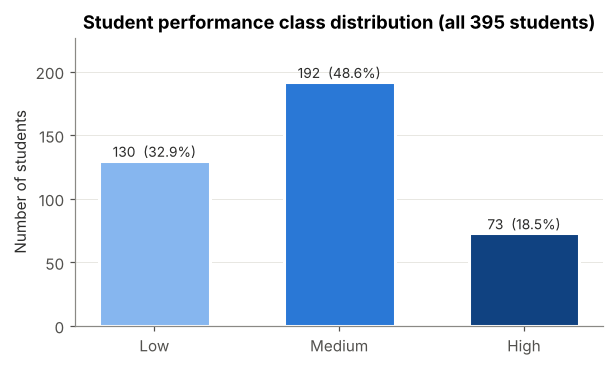

saved -> results/01_gd_class_distribution.png


In [7]:
fig, ax = plt.subplots(figsize=(6.2, 3.4))
counts = dist["count"].to_numpy()
bars = ax.bar(CLASS_NAMES, counts, color=CLASS_COLORS, width=0.6, edgecolor="white", linewidth=2)
for b, c, s in zip(bars, counts, dist["share_%"]):
    ax.text(b.get_x() + b.get_width() / 2, c + 3, f"{c}  ({s}%)", ha="center", color=INK, fontsize=9)
ax.set_title("Student performance class distribution (all 395 students)")
ax.set_ylabel("Number of students"); ax.set_ylim(0, counts.max() * 1.18); ax.grid(axis="x", visible=False)
save_fig(fig, "01_gd_class_distribution")

## 4. Train/test split and preprocessing

* Stratified 80/20 split with `random_state=42` → 316 training and 79 test students, same class proportions.
* Binary yes/no attributes → one 0/1 column; nominal attributes (`Mjob`, `Fjob`, `reason`, `guardian`) → one-hot columns; ordinal/numeric attributes kept as numbers.
* All encoded columns are standardized (zero mean, unit variance) so that gate values are comparable across attributes.
* The encoder and scaler are **fitted on the training rows only**, then applied to the test rows.

In [8]:
# One stratified split with a fixed seed -> the SAME train/test partition in all five notebooks
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)
TRAIN_IDX, TEST_IDX = X_train.index.to_numpy(), X_test.index.to_numpy()   # original row numbers
SPLIT_FINGERPRINT = hashlib.md5(np.sort(TEST_IDX).astype(np.int64).tobytes()).hexdigest()[:12]
X_train, X_test = X_train.reset_index(drop=True), X_test.reset_index(drop=True)

split_table = pd.DataFrame({
    "train": np.bincount(y_train, minlength=3), "test": np.bincount(y_test, minlength=3)}, index=CLASS_NAMES)
split_table.loc["total"] = split_table.sum()
display(split_table)
print(f"Test-set fingerprint: {SPLIT_FINGERPRINT}  (identical in every notebook -> same split)")

,train,test
Low,104,26
Medium,154,38
High,58,15
total,316,79


Test-set fingerprint: dbafa1e6d7d9  (identical in every notebook -> same split)


### Exploratory data analysis (training rows only)

EDA is computed on the 316 **training** students so that nothing about the test set influences any later decision.

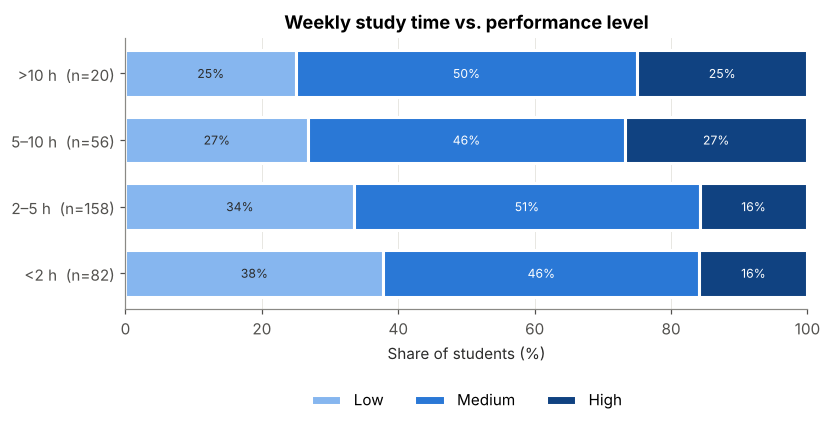

saved -> results/01_gd_studytime_vs_performance.png


In [9]:
eda = df.loc[TRAIN_IDX].copy()
eda["Performance"] = pd.Categorical(eda["Performance_Level"].map(dict(enumerate(CLASS_NAMES))), CLASS_NAMES)

def stacked_share(ax, col, labels, title):
    tab = pd.crosstab(eda[col], eda["Performance"], normalize="index") * 100
    n = eda[col].value_counts().reindex(tab.index)
    left = np.zeros(len(tab))
    for cls, colr in zip(CLASS_NAMES, CLASS_COLORS):
        ax.barh(range(len(tab)), tab[cls], left=left, color=colr, edgecolor="white", linewidth=2, height=0.7, label=cls)
        for i, (l, v) in enumerate(zip(left, tab[cls])):
            if v >= 9:
                ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=8,
                        color="white" if cls != "Low" else INK)
        left += tab[cls].to_numpy()
    ax.set_yticks(range(len(tab)), [f"{labels.get(i, i)}  (n={n[i]})" for i in tab.index])
    ax.set_xlim(0, 100); ax.set_xlabel("Share of students (%)"); ax.set_title(title); ax.grid(axis="y", visible=False)

fig, ax = plt.subplots(figsize=(8, 3.2))
stacked_share(ax, "studytime", {1: "<2 h", 2: "2–5 h", 3: "5–10 h", 4: ">10 h"}, "Weekly study time vs. performance level")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.25))
save_fig(fig, "01_gd_studytime_vs_performance")

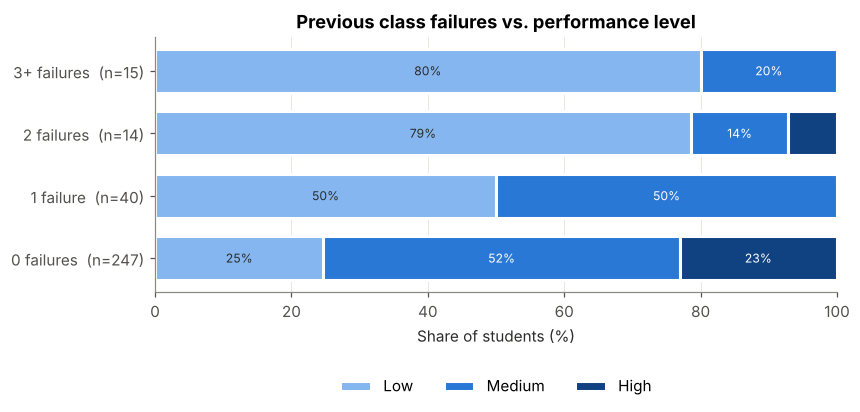

saved -> results/01_gd_failures_vs_performance.png


In [10]:
fig, ax = plt.subplots(figsize=(8, 3.0))
stacked_share(ax, "failures", {0: "0 failures", 1: "1 failure", 2: "2 failures", 3: "3+ failures"},
              "Previous class failures vs. performance level")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.28))
save_fig(fig, "01_gd_failures_vs_performance")

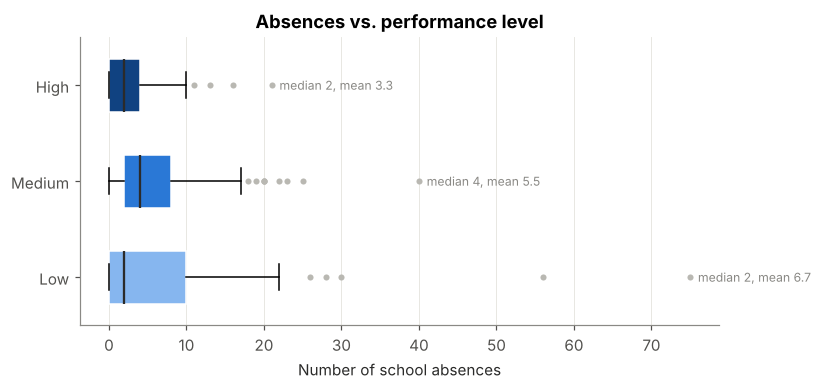

saved -> results/01_gd_absences_vs_performance.png


In [11]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
data = [eda.loc[eda["Performance"] == c, "absences"] for c in CLASS_NAMES]
bp = ax.boxplot(data, orientation="horizontal", patch_artist=True, widths=0.55, showfliers=True,
                medianprops=dict(color=INK, lw=1.5), flierprops=dict(marker="o", ms=4, mfc=NEUTRAL, mec="none"))
for patch, colr in zip(bp["boxes"], CLASS_COLORS):
    patch.set_facecolor(colr); patch.set_edgecolor("white")
ax.set_yticks([1, 2, 3], CLASS_NAMES)
for i, d in enumerate(data, start=1):
    ax.text(d.max() + 1, i, f"median {d.median():.0f}, mean {d.mean():.1f}", va="center", fontsize=8, color=MUTED)
ax.set_xlabel("Number of school absences"); ax.set_title("Absences vs. performance level"); ax.grid(axis="y", visible=False)
save_fig(fig, "01_gd_absences_vs_performance")

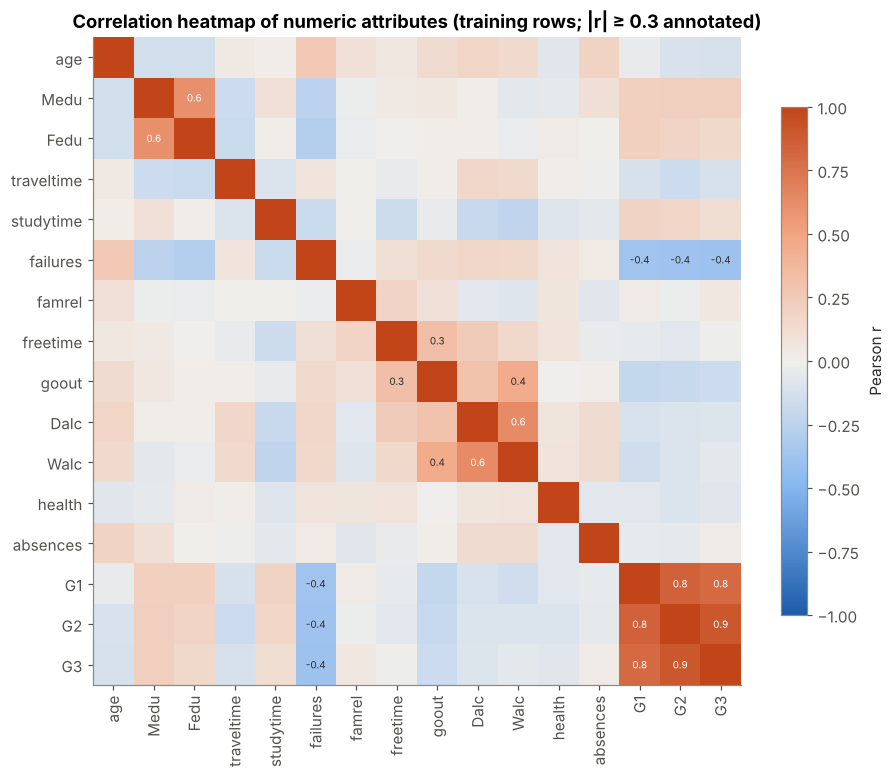

saved -> results/01_gd_correlation_heatmap.png
Correlation with G3: {'G2': 0.9, 'G1': 0.8, 'failures': -0.39, 'Medu': 0.21, 'goout': -0.17, 'Fedu': 0.16, 'age': -0.12, 'studytime': 0.12}


In [12]:
num_cols = eda.select_dtypes("number").columns.drop("Performance_Level")
corr = eda[num_cols].corr()
fig, ax = plt.subplots(figsize=(9.5, 8))
im = ax.imshow(corr, cmap=DIV_CMAP, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90); ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        if abs(corr.iloc[i, j]) >= 0.3 and i != j:
            ax.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=6.5,
                    color="white" if abs(corr.iloc[i, j]) > 0.6 else INK)
ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.75, label="Pearson r")
ax.set_title("Correlation heatmap of numeric attributes (training rows; |r| ≥ 0.3 annotated)")
save_fig(fig, "01_gd_correlation_heatmap")
print("Correlation with G3:", corr["G3"].drop("G3").sort_values(key=abs, ascending=False).round(2).head(8).to_dict())

**EDA observations (training rows).** Previous `failures` are the clearest non-grade warning sign: the share of *Low* performers rises from 25 % (no previous failure) to 50 % (one) and ≈80 % (two or more), although only 69 of the 316 training students have any failure. Study time shows a weaker, monotone pattern (*Low* share 38 % for <2 h vs. 25 % for >10 h per week). Absences are highly skewed (a few students above 50); surprisingly, 40 % of *Low* students have 0 recorded absences (vs. 25 % of the others) – all 31 training students with G3 = 0, probable drop-outs, have 0 absences. G1 and G2 correlate very strongly with G3 (r = 0.80 and 0.90), which is why they are excluded from the early-warning scenario.

In [13]:
def build_preprocessor(frame):
    """One-hot encode categorical attributes, then standardise every column.
    Returns an UNFITTED pipeline: it is always fitted on training rows only."""
    cat_cols = [c for c in frame.columns if not pd.api.types.is_numeric_dtype(frame[c])]
    num_cols = [c for c in frame.columns if c not in cat_cols]
    encoder = ColumnTransformer([
        ("num", "passthrough", num_cols),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), cat_cols),
    ], verbose_feature_names_out=False)
    return Pipeline([("encode", encoder), ("scale", StandardScaler())]), cat_cols, num_cols


def prepare(frame_fit, frame_apply=None):
    """Fit preprocessing on `frame_fit` ONLY and transform both frames.
    Also returns `gidx`: for every encoded column, the index of the original attribute it came from
    (one-hot columns of the same attribute share one feature gate)."""
    pre, cat_cols, _ = build_preprocessor(frame_fit)
    Z_fit = pre.fit_transform(frame_fit)
    names = list(pre.named_steps["encode"].get_feature_names_out())
    attrs = list(frame_fit.columns)
    gidx = []
    for n in names:
        if n in attrs:
            gidx.append(attrs.index(n))
        else:
            owner = [c for c in cat_cols if n.startswith(c + "_")]
            assert len(owner) == 1, n
            gidx.append(attrs.index(owner[0]))
    Z_apply = pre.transform(frame_apply) if frame_apply is not None else None
    return Z_fit, Z_apply, np.array(gidx), attrs, names, pre


Z_train, Z_test, GIDX, ATTRS, ENCODED, PRE = prepare(X_train, X_test)
N_ATTR = len(ATTRS)
_, CAT_COLS, NUM_COLS = build_preprocessor(X_train)
print(f"Numerical attributes ({len(NUM_COLS)}): {NUM_COLS}")
print(f"Categorical attributes ({len(CAT_COLS)}): {CAT_COLS}")
print(f"Encoded design matrix: train {Z_train.shape}, test {Z_test.shape} "
      f"({N_ATTR} attributes -> {len(ENCODED)} columns)")

# Leakage check: the scaler statistics must equal the TRAINING-set statistics
enc_train = PRE.named_steps["encode"].transform(X_train)
assert np.allclose(PRE.named_steps["scale"].mean_, enc_train.mean(axis=0))
print("Leakage check passed: scaler/encoder fitted on the 316 training rows only "
      f"(test-column means after scaling are not forced to 0: max |mean| = {np.abs(Z_test.mean(0)).max():.3f})")

Numerical attributes (13): ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']
Categorical attributes (17): ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']
Encoded design matrix: train (316, 43), test (79, 43) (30 attributes -> 43 columns)
Leakage check passed: scaler/encoder fitted on the 316 training rows only (test-column means after scaling are not forced to 0: max |mean| = 0.332)


## 5. Differentiable feature-selection surrogate (PyTorch)

The same model class, objective and initialization are used in all five notebooks. Autograd computes the gradient $\nabla\mathcal L$; **the optimizer only decides how to turn that gradient into a parameter update** – which is exactly the part that differs between the five experiments.

In [14]:
class GatedSoftmaxSurrogate(torch.nn.Module):
    """Input -> differentiable feature gates -> multinomial logistic regression.
    One non-negative gate g_a = softplus(gamma_a) per ORIGINAL attribute a."""
    def __init__(self, n_inputs, gidx, n_groups, n_classes=3, seed=SEED):
        super().__init__()
        gen = torch.Generator().manual_seed(seed)                       # same initial weights for every optimizer
        self.gate_logits = torch.nn.Parameter(torch.full((n_groups,), GATE_INIT))
        self.W = torch.nn.Parameter(0.01 * torch.randn(n_inputs, n_classes, generator=gen))
        self.b = torch.nn.Parameter(torch.zeros(n_classes))
        self.register_buffer("gidx", torch.as_tensor(gidx, dtype=torch.long))

    def gates(self):
        return torch.nn.functional.softplus(self.gate_logits)

    def forward(self, X):
        return (X * self.gates()[self.gidx]) @ self.W + self.b          # logits


def objective(model, X, y, lam):
    """Cross-entropy + gate sparsity penalty + weight decay (the loss every optimizer minimises)."""
    lam_gate, lam_w = lam
    ce = torch.nn.functional.cross_entropy(model(X), y)
    return ce + lam_gate * model.gates().mean() + lam_w * (model.W ** 2).sum()


def to_tensors(Z, y):
    return torch.as_tensor(Z), torch.as_tensor(y, dtype=torch.long)


def validation_ce(model, Z, y):
    X_, y_ = to_tensors(Z, y)
    with torch.no_grad():
        return torch.nn.functional.cross_entropy(model(X_), y_).item()


def rank_attributes(model):
    """Attributes ordered by learned gate (ranked on the gate logits: same order as softplus(gamma),
    but free of floating-point ties when several gates are numerically ~0)."""
    return np.argsort(-model.gate_logits.detach().numpy(), kind="stable")


def columns_for(attr_ids, gidx):
    return np.where(np.isin(gidx, attr_ids))[0]

In [15]:
def train_reference(Z, y, gidx, n_groups, lam):
    """Optimizer-neutral reference solution of the SAME objective (full-batch L-BFGS).
    Used only (i) to calibrate the shared regularisation, (ii) to choose the shared feature budget,
    and (iii) as the 'true optimum' when measuring how fast each of the five optimizers converges.
    It is NOT one of the five compared optimizers."""
    X_, y_ = to_tensors(Z, y)
    model = GatedSoftmaxSurrogate(X_.shape[1], gidx, n_groups)
    lbfgs = torch.optim.LBFGS(model.parameters(), lr=1.0, max_iter=2000, tolerance_grad=1e-10,
                              tolerance_change=1e-14, history_size=50, line_search_fn="strong_wolfe")
    def closure():
        lbfgs.zero_grad()
        loss = objective(model, X_, y_, lam)
        loss.backward()
        return loss
    lbfgs.step(closure)
    with torch.no_grad():
        return model, objective(model, X_, y_, lam).item()

In [16]:
def train_surrogate(Z, y, gidx, n_groups, spec, lr, lam, epochs=EPOCHS, seed=SEED,
                    log_steps_epochs=0, callback=None):
    """Train the gated surrogate with one optimizer.
    spec['batch'] = None -> full batch (Batch GD); 1 -> SGD; b -> mini-batches of size b.
    Returns the model, the full-training-set objective after every epoch, the pure update time (s)
    and (optionally) the per-update mini-batch losses of the first `log_steps_epochs` epochs."""
    X_, y_ = to_tensors(Z, y)
    model = GatedSoftmaxSurrogate(X_.shape[1], gidx, n_groups, seed=seed)
    opt = spec["cls"](model.parameters(), lr=lr, **spec.get("kwargs", {}))
    n = len(X_)
    bs = n if spec["batch"] is None else spec["batch"]
    gen = torch.Generator().manual_seed(seed)        # identical shuffling sequence for every optimizer
    history, step_losses, update_time = [], [], 0.0
    for epoch in range(epochs):
        t0 = time.perf_counter()
        batches = [torch.arange(n)] if bs >= n else torch.randperm(n, generator=gen).split(bs)
        for idx in batches:
            model.zero_grad()
            loss = objective(model, X_[idx], y_[idx], lam)
            loss.backward()                              # autograd computes the gradient
            opt.step()                                   # the optimizer decides how to use it
            if epoch < log_steps_epochs:
                step_losses.append(loss.item())
        update_time += time.perf_counter() - t0          # monitoring below is excluded from timing
        with torch.no_grad():
            history.append(objective(model, X_, y_, lam).item())
        if callback is not None:
            callback(epoch, model, opt)
        if not np.isfinite(history[-1]):
            break
    return model, np.array(history), update_time, np.array(step_losses)


def epochs_to_target(history, reference_loss, tol=TARGET_TOL):
    hit = np.where(history <= reference_loss + tol)[0]
    return int(hit[0] + 1) if len(hit) else None

## 6. The optimizer: Batch Gradient Descent

### 6.1 Introduction
**Batch Gradient Descent** computes the gradient of the loss over the **entire training set** and takes one step downhill per pass (epoch). It is the most basic first-order optimizer and the reference point for the other four.

### 6.2 Mathematical formulation
For parameters $\theta=(\gamma, W, b)$ and the full-data loss $\mathcal L(\theta)=\frac1n\sum_{i=1}^{n}\ell_i(\theta)+\text{penalties}$:

$$\theta_{t+1}=\theta_t-\alpha\,\nabla_\theta\mathcal L(\theta_t)$$

* **Learning rate $\alpha$** – step size. Too small → very slow progress; too large → oscillation or divergence. For a smooth objective with gradient-Lipschitz constant $L_s$, GD is stable for $\alpha<2/L_s$.
* **One update per epoch** – with $n=316$ training students, 150 epochs = only **150 updates**.
* **Deterministic** – no sampling noise: the loss decreases smoothly (for a suitable $\alpha$).

### 6.3 Gradient calculation for our surrogate
With $Z=X\odot g_{\pi}$, $P=\operatorname{softmax}(ZW+b)$ and one-hot labels $Y$, let $D=(P-Y)/n$. Then

$$\nabla_W\mathcal L = Z^\top D + 2\lambda_w W,\qquad \nabla_b\mathcal L=\textstyle\sum_i D_i,$$
$$\frac{\partial\mathcal L}{\partial \gamma_a}=\sigma(\gamma_a)\Big[\sum_{j:\pi(j)=a}\sum_i X_{ij}\,(DW^\top)_{ij}+\frac{\lambda_g}{A}\Big],$$
using $\operatorname{softplus}'(\gamma)=\sigma(\gamma)$ (the logistic sigmoid). Below, these hand-derived gradients are checked against PyTorch autograd.

In [17]:
class GradientDescent:
    """Plain gradient-descent update  θ <- θ − α·∇L(θ), written from scratch.
    Batch GD, SGD and Mini-Batch GD all use THIS rule; they differ only in how many
    training samples are used to estimate ∇L at each update (all n, 1, or a mini-batch of b)."""
    def __init__(self, params, lr):
        self.params, self.lr = list(params), lr

    @torch.no_grad()
    def step(self):
        for p in self.params:
            p -= self.lr * p.grad

In [18]:
SPEC = {"name": "GD", "cls": GradientDescent, "batch": None, "grid": [0.1, 0.3, 1.0, 3.0], "kwargs": {}, "color": OPT_COLORS["GD"]}
print('Optimizer spec:', {k: v for k, v in SPEC.items() if k != 'cls'})

Optimizer spec: {'name': 'GD', 'batch': None, 'grid': [0.1, 0.3, 1.0, 3.0], 'kwargs': {}, 'color': '#2a78d6'}


### Verifying the from-scratch implementation

The update rule above is implemented by hand. To prove it is correct, it is run side by side with PyTorch's built-in optimizer for 200 updates on identical batches from identical initial weights; the parameters must agree to floating-point precision.

In [19]:
def verify_against_torch(spec, torch_factory, steps=200, lr=0.01, lam=(0.1, 0.3)):
    """Run our from-scratch optimizer and PyTorch's built-in one side by side on identical
    batches from identical initial weights; return the largest parameter difference."""
    X_, y_ = to_tensors(Z_train, y_train)
    ours, ref = (GatedSoftmaxSurrogate(X_.shape[1], GIDX, N_ATTR) for _ in range(2))
    opt_ours = spec["cls"](ours.parameters(), lr=lr, **spec.get("kwargs", {}))
    opt_ref = torch_factory(ref.parameters(), lr)
    gen, n = torch.Generator().manual_seed(0), len(X_)
    bs = n if spec["batch"] is None else spec["batch"]
    for _ in range(steps):
        idx = torch.arange(n) if bs >= n else torch.randperm(n, generator=gen)[:bs]
        for m, o in ((ours, opt_ours), (ref, opt_ref)):
            m.zero_grad()
            objective(m, X_[idx], y_[idx], lam).backward()
            o.step()
    return max((a - b).abs().max().item() for a, b in zip(ours.parameters(), ref.parameters()))

diff = verify_against_torch(SPEC, lambda p, lr: torch.optim.SGD(p, lr=lr))
print(f"Max |θ_ours − θ_torch| after 200 updates: {diff:.2e}")
assert diff < 1e-10, 'implementation mismatch'
print('Implementation verified ✔')

Max |θ_ours − θ_torch| after 200 updates: 5.55e-17
Implementation verified ✔


### 6.4 Checking the hand-derived gradient against autograd

In [20]:
def analytic_gradients(model, X_, y_, lam):
    lam_gate, lam_w = lam
    g = model.gates()
    Zg = X_ * g[model.gidx]
    P = torch.softmax(Zg @ model.W + model.b, dim=1)
    D = (P - torch.nn.functional.one_hot(y_, 3).to(P.dtype)) / len(X_)
    dW = Zg.T @ D + 2 * lam_w * model.W
    db = D.sum(0)
    d_gate_cols = (X_ * (D @ model.W.T)).sum(0)                       # dCE / d(gate of each encoded column)
    d_g = torch.zeros_like(g).index_add_(0, model.gidx, d_gate_cols) + lam_gate / len(g)
    d_gamma = d_g * torch.sigmoid(model.gate_logits)                  # chain rule through softplus
    return d_gamma, dW, db

X_t, y_t = to_tensors(Z_train, y_train)
m = GatedSoftmaxSurrogate(X_t.shape[1], GIDX, N_ATTR)
with torch.no_grad():                                                 # move away from the symmetric start
    m.gate_logits.add_(0.3 * torch.randn(N_ATTR, generator=torch.Generator().manual_seed(1)))
objective(m, X_t, y_t, (0.1, 0.3)).backward()
with torch.no_grad():
    manual = analytic_gradients(m, X_t, y_t, (0.1, 0.3))
for name, a, b in zip(["γ (gates)", "W", "b"], manual, [m.gate_logits.grad, m.W.grad, m.b.grad]):
    print(f"{name:10s} max |analytic − autograd| = {(a - b).abs().max().item():.2e}")

γ (gates)  max |analytic − autograd| = 1.73e-18
W          max |analytic − autograd| = 2.78e-17
b          max |analytic − autograd| = 6.94e-18


## 7. Shared, optimizer-neutral protocol choices (training data only)

Two settings must be **identical for every optimizer**, so they are chosen with an optimizer-neutral reference solver (full-batch L-BFGS on the same objective) – never with the test set:

* **Stage A – surrogate regularization** $(\lambda_g,\lambda_w)$: 5-fold stratified CV, lowest validation cross-entropy.
* **Stage B – feature budget $K$**: 5×3 repeated stratified CV of "rank attributes by gate → Random Forest on top-$k$", scored by macro-F1; the **one-standard-error rule** (smallest $k$ within 1 SE of the best mean) was fixed before looking at the results, favouring compact subsets on this small dataset.

Because these steps are deterministic, every notebook recomputes exactly the same values.

In [21]:
def calibrate_regularisation(X_tr, y_tr):
    """Stage A (optimizer-neutral): choose (lambda_gate, lambda_w) of the surrogate by 5-fold
    stratified CV inside the training set, using the reference solver and validation cross-entropy."""
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    folds = [(prepare(X_tr.iloc[a], X_tr.iloc[b]), a, b) for a, b in skf.split(X_tr, y_tr)]
    rows = []
    for lam in LAMBDA_GRID:
        ce, active = [], []
        for (Za, Zb, gi, at, _, _), a, b in folds:
            m, _ = train_reference(Za, y_tr[a], gi, len(at), lam)
            ce.append(validation_ce(m, Zb, y_tr[b]))
            active.append(int((m.gates() > 1e-3).sum()))
        rows.append(dict(lambda_gate=lam[0], lambda_w=lam[1], val_ce_mean=np.mean(ce),
                         val_ce_std=np.std(ce), active_gates=np.mean(active)))
    table = pd.DataFrame(rows)
    best = table.loc[table["val_ce_mean"].idxmin()]
    prior_ce = np.mean([-np.log(np.bincount(y_tr[a], minlength=3)[y_tr[b]] / len(a)).mean()
                        for _, a, b in folds])
    return (float(best["lambda_gate"]), float(best["lambda_w"])), table, prior_ce


t0 = time.perf_counter()
LAM, lam_table, PRIOR_CE = calibrate_regularisation(X_train, y_train)
display(lam_table.round(4))
print(f"Chosen surrogate regularisation: lambda_gate = {LAM[0]}, lambda_w = {LAM[1]} "
      f"| class-prior baseline CE = {PRIOR_CE:.4f} | {time.perf_counter() - t0:.0f}s")

,lambda_gate,lambda_w,val_ce_mean,val_ce_std,active_gates
0,0.05,0.1,1.0387,0.0748,15.4
1,0.05,0.3,1.0101,0.0525,12.0
2,0.05,1.0,0.9884,0.0319,7.4
3,0.10,0.1,1.0081,0.0444,9.6
4,0.10,0.3,0.9826,0.0308,7.0
5,0.10,1.0,0.9584,0.0185,3.8
6,0.20,0.1,0.9747,0.0257,6.0
7,0.20,0.3,0.9577,0.0181,3.0
8,0.20,1.0,0.9671,0.0223,1.6
9,0.40,0.1,0.9696,0.0262,2.4


Chosen surrogate regularisation: lambda_gate = 0.2, lambda_w = 0.3 | class-prior baseline CE = 1.0273 | 56s


,0,1,2,3,4,5,6,7,8,9,10,11,12
k,1.0000,2.0000,3.0000,4.0000,5.0000,6.0000,8.0000,10.0000,12.0000,15.0000,20.0000,25.0000,30.0000
cv_macro_f1_mean,0.3434,0.3262,0.4124,0.4365,0.4470,0.4407,0.4462,0.4492,0.4409,0.4270,0.4222,0.4060,0.4013
cv_macro_f1_std,0.0445,0.0467,0.0708,0.0369,0.0741,0.0545,0.0526,0.0672,0.0619,0.0482,0.0724,0.0598,0.0590


Best mean CV macro-F1 at k = 10; 1-SE rule -> shared feature budget K = 4 attributes (of 30) | 45s


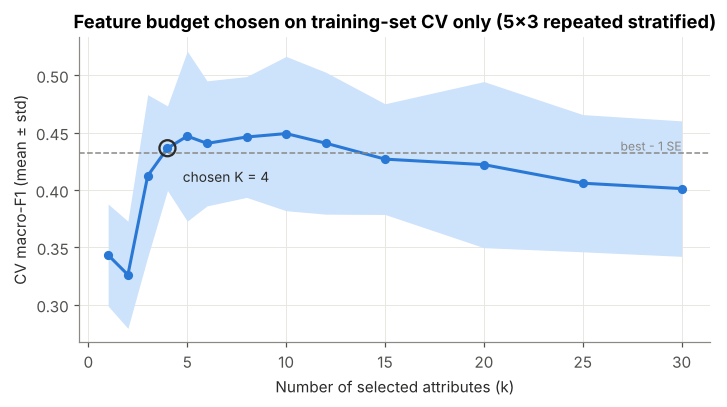

saved -> results/01_gd_feature_budget_cv.png


In [22]:
def choose_feature_budget(X_tr, y_tr, lam):
    """Stage B (optimizer-neutral): choose ONE feature budget k for all pipelines.
    5x3 repeated stratified CV inside the training set: in every fold the preprocessing and the
    reference surrogate are fitted on the fold-train part only, attributes are ranked by gate, and a
    Random Forest on the top-k attributes is scored (macro-F1) on the fold-validation part.
    Rule fixed in advance: the smallest k within one standard error of the best mean (1-SE rule)."""
    rcv = RepeatedStratifiedKFold(n_splits=CV_SPLITS, n_repeats=CV_REPEATS, random_state=SEED)
    k_grid = [k for k in K_GRID if k <= X_tr.shape[1]]
    if X_tr.shape[1] not in k_grid:
        k_grid.append(X_tr.shape[1])
    scores = {k: [] for k in k_grid}
    for a, b in rcv.split(X_tr, y_tr):
        Za, Zb, gi, at, _, _ = prepare(X_tr.iloc[a], X_tr.iloc[b])
        ref, _ = train_reference(Za, y_tr[a], gi, len(at), lam)
        order = rank_attributes(ref)
        for k in k_grid:
            cols = columns_for(order[:k], gi)
            rf = RandomForestClassifier(**RF_PARAMS).fit(Za[:, cols], y_tr[a])
            scores[k].append(f1_score(y_tr[b], rf.predict(Zb[:, cols]), average="macro"))
    table = pd.DataFrame({"k": k_grid, "cv_macro_f1_mean": [np.mean(scores[k]) for k in k_grid],
                          "cv_macro_f1_std": [np.std(scores[k]) for k in k_grid]})
    best = table.loc[table["cv_macro_f1_mean"].idxmax()]
    se = best["cv_macro_f1_std"] / np.sqrt(CV_SPLITS * CV_REPEATS)
    k_star = int(table.loc[table["cv_macro_f1_mean"] >= best["cv_macro_f1_mean"] - se, "k"].min())
    return k_star, table, int(best["k"]), se


t0 = time.perf_counter()
K, k_table, K_BEST, K_SE = choose_feature_budget(X_train, y_train, LAM)
display(k_table.round(4).T)
print(f"Best mean CV macro-F1 at k = {K_BEST}; 1-SE rule -> shared feature budget K = {K} "
      f"attributes (of {N_ATTR}) | {time.perf_counter() - t0:.0f}s")

fig, ax = plt.subplots(figsize=(7.4, 3.6))
ax.fill_between(k_table["k"], k_table["cv_macro_f1_mean"] - k_table["cv_macro_f1_std"],
                k_table["cv_macro_f1_mean"] + k_table["cv_macro_f1_std"], color=BLUE_RAMP[0], lw=0)
ax.plot(k_table["k"], k_table["cv_macro_f1_mean"], color=ACCENT, lw=2, marker="o", ms=5)
thr = k_table["cv_macro_f1_mean"].max() - K_SE
ax.axhline(thr, color=MUTED, lw=1, ls="--")
ax.text(k_table["k"].max(), thr, " best - 1 SE", va="bottom", ha="right", color=MUTED, fontsize=8)
ax.scatter([K], k_table.set_index("k").loc[K, "cv_macro_f1_mean"], s=110, facecolor="none",
           edgecolor=INK, lw=1.5, zorder=5)
ax.annotate(f"chosen K = {K}", (K, k_table.set_index("k").loc[K, "cv_macro_f1_mean"]),
            xytext=(10, -22), textcoords="offset points", color=INK, fontsize=9)
ax.set_xlabel("Number of selected attributes (k)"); ax.set_ylabel("CV macro-F1 (mean ± std)")
ax.set_title("Feature budget chosen on training-set CV only (5x3 repeated stratified)")
save_fig(fig, "01_gd_feature_budget_cv")

## 8. Learning-rate tuning for this optimizer (training data only)

The learning rate is the one setting that is legitimately optimizer-specific. It is selected from a log-spaced grid by 3-fold stratified CV on the training set (criterion: mean validation cross-entropy of the surrogate after the fixed 150-epoch budget). The dashed line marks the cross-entropy of a model that always predicts the class prior.

In [23]:
def tune_learning_rate(X_tr, y_tr, spec, lam):
    """Stage C (optimizer-specific): pick the learning rate from the optimizer's own grid by
    stratified CV inside the training set (criterion: mean validation cross-entropy)."""
    skf = StratifiedKFold(n_splits=LR_FOLDS, shuffle=True, random_state=SEED)
    folds = [(prepare(X_tr.iloc[a], X_tr.iloc[b]), a, b) for a, b in skf.split(X_tr, y_tr)]
    rows = []
    for lr in spec["grid"]:
        ce = []
        for (Za, Zb, gi, at, _, _), a, b in folds:
            m, hist, _, _ = train_surrogate(Za, y_tr[a], gi, len(at), spec, lr, lam)
            ce.append(validation_ce(m, Zb, y_tr[b]) if np.isfinite(hist[-1]) else np.inf)
        rows.append(dict(learning_rate=lr, val_ce_mean=np.mean(ce), val_ce_std=np.std(ce)))
    table = pd.DataFrame(rows)
    return float(table.loc[table["val_ce_mean"].idxmin(), "learning_rate"]), table


def plot_lr_table(table, name, chosen, color, fname):
    fig, ax = plt.subplots(figsize=(5.6, 3.2))
    ax.errorbar(table["learning_rate"], table["val_ce_mean"], yerr=table["val_ce_std"], color=color,
                lw=2, marker="o", ms=6, capsize=3)
    ax.axhline(PRIOR_CE, color=MUTED, lw=1, ls="--")
    ax.text(table["learning_rate"].min(), PRIOR_CE, "class-prior CE", va="bottom", color=MUTED, fontsize=8)
    best = table.set_index("learning_rate").loc[chosen, "val_ce_mean"]
    ax.scatter([chosen], [best], s=120, facecolor="none", edgecolor=INK, lw=1.5, zorder=5)
    ax.set_xscale("log"); ax.set_xlabel("Learning rate α (log scale)")
    ax.set_ylabel("Validation cross-entropy"); ax.set_title(f"{name}: learning-rate tuning ({LR_FOLDS}-fold CV)")
    save_fig(fig, fname)

,learning_rate,val_ce_mean,val_ce_std
0,0.1,0.9747,0.0050
1,0.3,0.9720,0.0045
2,1.0,0.9918,0.0138
3,3.0,1.0215,0.0060


Chosen learning rate for GD: α = 0.3  (tuning took 1s)


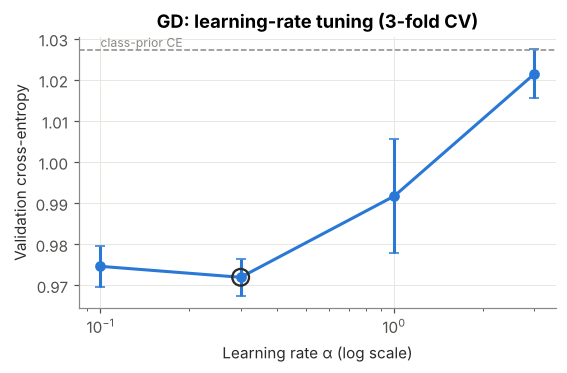

saved -> results/01_gd_lr_tuning.png


In [24]:
t0 = time.perf_counter()
BEST_LR, lr_table = tune_learning_rate(X_train, y_train, SPEC, LAM)
LR_TUNING_TIME = time.perf_counter() - t0
display(lr_table.round(4))
print(f"Chosen learning rate for {SPEC['name']}: α = {BEST_LR}  (tuning took {LR_TUNING_TIME:.0f}s)")
plot_lr_table(lr_table, SPEC["name"], BEST_LR, SPEC["color"], "01_gd_lr_tuning")

## 9. Final feature selection, convergence and the selected subset

The surrogate is retrained on the full training set with the tuned learning rate. Convergence is measured against the **reference optimum** of the same objective (L-BFGS): *epochs-to-target* is the first epoch at which the training objective is within 0.02 of that optimum.

In [25]:
def compute_metrics(y_true, y_pred, proba):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        # multiclass ROC-AUC: one-vs-rest, macro-averaged over the three classes, from predicted probabilities
        "roc_auc_ovr_macro": roc_auc_score(y_true, proba, multi_class="ovr", average="macro"),
    }


def bootstrap_ci(y_true, y_pred, n=N_BOOTSTRAP):
    """95% percentile bootstrap intervals for test accuracy and macro-F1 (79 test students -> wide)."""
    rng = np.random.default_rng(SEED)
    acc, f1 = [], []
    for _ in range(n):
        i = rng.integers(0, len(y_true), len(y_true))
        acc.append(accuracy_score(y_true[i], y_pred[i]))
        f1.append(f1_score(y_true[i], y_pred[i], average="macro", labels=[0, 1, 2], zero_division=0))
    return np.percentile(acc, [2.5, 97.5]), np.percentile(f1, [2.5, 97.5])


def rf_evaluate(Z_tr, y_tr, Z_te, y_te, cols):
    """Train the (fixed-configuration) Random Forest on the chosen columns and evaluate it on the test set."""
    rf = RandomForestClassifier(**RF_PARAMS)
    t0 = time.perf_counter()
    rf.fit(Z_tr[:, cols], y_tr)
    fit_time = time.perf_counter() - t0
    pred, proba = rf.predict(Z_te[:, cols]), rf.predict_proba(Z_te[:, cols])
    acc_ci, f1_ci = bootstrap_ci(y_te, pred)
    return dict(model=rf, cols=cols, fit_time=fit_time, pred=pred, proba=proba,
                metrics=compute_metrics(y_te, pred, proba), acc_ci=acc_ci, f1_ci=f1_ci,
                cm=confusion_matrix(y_te, pred, labels=[0, 1, 2]),
                report=classification_report(y_te, pred, labels=[0, 1, 2], target_names=CLASS_NAMES,
                                             zero_division=0))


def rf_importance_by_attribute(rf, cols, gidx, attrs):
    """Random Forest's OWN impurity-based (MDI) importance, summed over the one-hot columns of each attribute."""
    imp = pd.Series(0.0, index=attrs)
    for c, v in zip(cols, rf.feature_importances_):
        imp[attrs[gidx[c]]] += v
    return imp[imp > 0].sort_values(ascending=False)


def cv_pipeline(X_tr, y_tr, spec=None, lr=None, lam=None, k=None):
    """Repeated stratified CV (5x3) of a FULL pipeline inside the training set, to measure variability.
    spec=None -> all-feature baseline. Feature selection is re-done inside every fold (no leakage)."""
    rcv = RepeatedStratifiedKFold(n_splits=CV_SPLITS, n_repeats=CV_REPEATS, random_state=SEED)
    acc, f1 = [], []
    for a, b in rcv.split(X_tr, y_tr):
        Za, Zb, gi, at, _, _ = prepare(X_tr.iloc[a], X_tr.iloc[b])
        if spec is None:
            cols = np.arange(Za.shape[1])
        else:
            m, _, _, _ = train_surrogate(Za, y_tr[a], gi, len(at), spec, lr, lam)
            cols = columns_for(rank_attributes(m)[:k], gi)
        rf = RandomForestClassifier(**RF_PARAMS).fit(Za[:, cols], y_tr[a])
        pred = rf.predict(Zb[:, cols])
        acc.append(accuracy_score(y_tr[b], pred))
        f1.append(f1_score(y_tr[b], pred, average="macro"))
    return np.array(acc), np.array(f1)


def plot_confusion(ax, cm, title):
    ax.imshow(cm, cmap=SEQ_CMAP, vmin=0, vmax=max(cm.max(), 1))
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=11,
                    color="white" if cm[i, j] > 0.55 * cm.max() else INK)
    ax.set_xticks(range(3), CLASS_NAMES); ax.set_yticks(range(3), CLASS_NAMES)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(title, fontsize=10); ax.grid(False)

In [26]:
def plot_convergence(history, reference_loss, name, color, fname, extra=None):
    """Left: training objective per epoch. Right: gap to the reference optimum on a log scale."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    ep = np.arange(1, len(history) + 1)
    axes[0].plot(ep, history, color=color, lw=2, label=name)
    if extra is not None:
        for lbl, (h, c) in extra.items():
            axes[0].plot(np.arange(1, len(h) + 1), h, color=c, lw=2, label=lbl)
    axes[0].axhline(reference_loss, color=INK, lw=1, ls="--")
    axes[0].text(len(history), reference_loss, "reference optimum (L-BFGS)", ha="right", va="bottom", fontsize=8)
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Training objective"); axes[0].set_title("Loss convergence")
    axes[1].plot(ep, np.maximum(history - reference_loss, 1e-6), color=color, lw=2, label=name)
    if extra is not None:
        for lbl, (h, c) in extra.items():
            axes[1].plot(np.arange(1, len(h) + 1), np.maximum(h - reference_loss, 1e-6), color=c, lw=2, label=lbl)
    axes[1].axhline(TARGET_TOL, color=MUTED, lw=1, ls=":")
    axes[1].text(1, TARGET_TOL, f"target tolerance {TARGET_TOL}", va="bottom", color=MUTED, fontsize=8)
    axes[1].set_yscale("log"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Objective − optimum (log)")
    axes[1].set_title("Distance to the optimum")
    if extra is not None:
        axes[0].legend(); axes[1].legend()
    fig.tight_layout()
    save_fig(fig, fname)

In [27]:
# Final feature selection on the FULL training set with the tuned learning rate
REF_MODEL, REF_LOSS = train_reference(Z_train, y_train, GIDX, N_ATTR, LAM)
model, history, fs_time, _ = train_surrogate(Z_train, y_train, GIDX, N_ATTR, SPEC, BEST_LR, LAM)
order = rank_attributes(model)
SELECTED = [ATTRS[i] for i in order[:K]]
SEL_COLS = columns_for(order[:K], GIDX)
gates = pd.Series(model.gates().detach().numpy(), index=ATTRS).sort_values(ascending=False)
E2T = epochs_to_target(history, REF_LOSS)

print(f"Optimizer: {SPEC['name']} | learning rate {BEST_LR} | batch size "
      f"{'full (' + str(len(y_train)) + ')' if SPEC['batch'] is None else SPEC['batch']} | epochs {EPOCHS}")
print(f"Updates performed: {EPOCHS * (1 if SPEC['batch'] is None else int(np.ceil(len(y_train) / SPEC['batch'])))}")
print(f"Feature-selection (surrogate training) time: {fs_time:.3f} s")
print(f"Objective: start {history[0]:.4f} -> final {history[-1]:.4f} | reference optimum {REF_LOSS:.4f} "
      f"| final gap {history[-1] - REF_LOSS:.4f}")
print(f"Epochs to reach optimum + {TARGET_TOL}: {E2T if E2T else 'not reached within ' + str(EPOCHS)}")
print(f"\nSelected K = {K} attributes: {SELECTED}")

Optimizer: GD | learning rate 0.3 | batch size full (316) | epochs 150
Updates performed: 150
Feature-selection (surrogate training) time: 0.056 s
Objective: start 1.2476 -> final 1.1318 | reference optimum 0.9864 | final gap 0.1453
Epochs to reach optimum + 0.02: not reached within 150

Selected K = 4 attributes: ['failures', 'Mjob', 'goout', 'schoolsup']


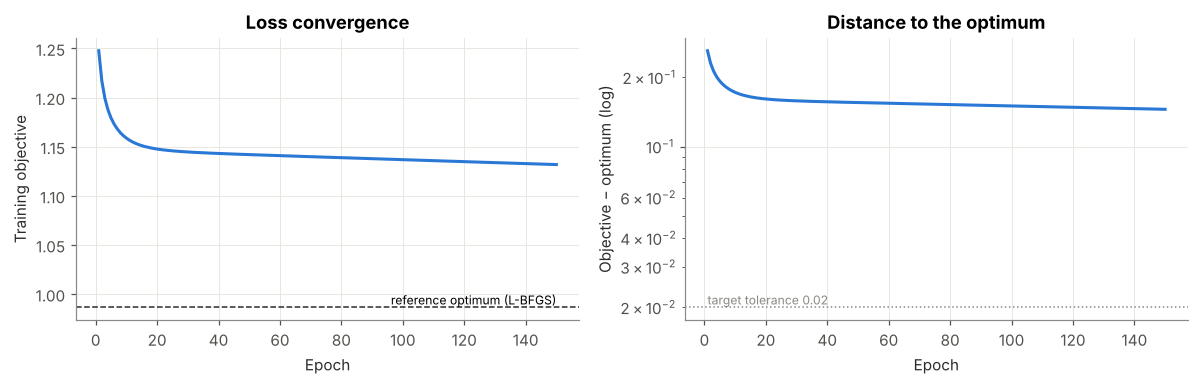

saved -> results/01_gd_loss_curve.png


In [28]:
plot_convergence(history, REF_LOSS, SPEC["name"], SPEC["color"], "01_gd_loss_curve")

### Effect of the learning rate (illustration on the training objective)

All four candidate learning rates trained on the full training set (the *choice* above was made by CV; this plot only illustrates the behaviour).

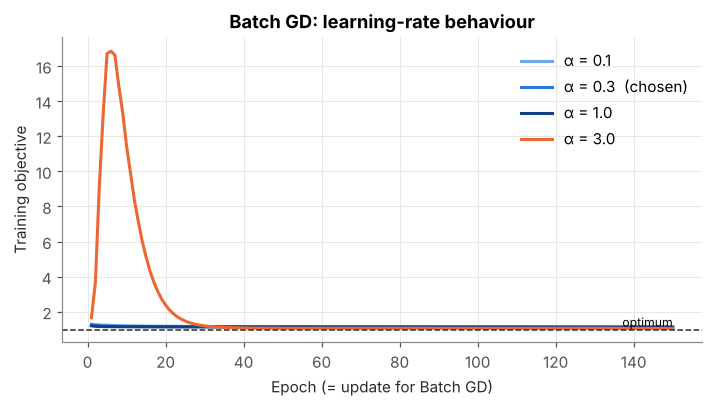

saved -> results/01_gd_learning_rate_effect.png


In [29]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for lr, colr in zip(SPEC["grid"], [BLUE_RAMP[2], BLUE_RAMP[4], BLUE_RAMP[6], "#eb6834"]):
    _, h, _, _ = train_surrogate(Z_train, y_train, GIDX, N_ATTR, SPEC, lr, LAM)
    ax.plot(np.arange(1, len(h) + 1), h, lw=2, color=colr, label=f"α = {lr}" + ("  (chosen)" if lr == BEST_LR else ""))
ax.axhline(REF_LOSS, color=INK, lw=1, ls="--"); ax.text(EPOCHS, REF_LOSS, "optimum", ha="right", va="bottom", fontsize=8)
ax.set_xlabel("Epoch (= update for Batch GD)"); ax.set_ylabel("Training objective")
ax.set_title("Batch GD: learning-rate behaviour"); ax.legend()
save_fig(fig, "01_gd_learning_rate_effect")

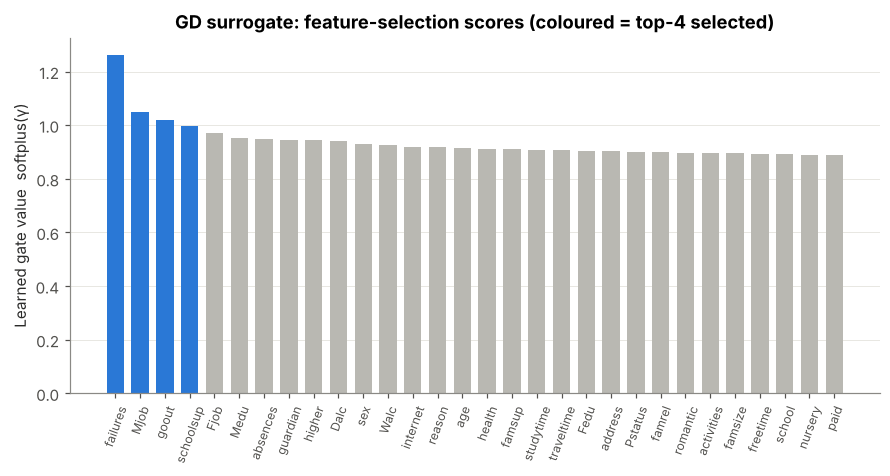

saved -> results/01_gd_gate_scores.png


In [30]:
fig, ax = plt.subplots(figsize=(9.5, 4.2))
cols_ = [SPEC["color"] if a in SELECTED else NEUTRAL for a in gates.index]
ax.bar(range(len(gates)), gates.to_numpy(), color=cols_, width=0.7)
ax.set_xticks(range(len(gates)), gates.index, rotation=70, fontsize=8); ax.grid(axis="x", visible=False)
ax.set_ylabel("Learned gate value  softplus(γ)")
ax.set_title(f"{SPEC['name']} surrogate: feature-selection scores (coloured = top-{K} selected)")
save_fig(fig, "01_gd_gate_scores")

## 10. Random Forest classification and evaluation

The Random Forest configuration is fixed (`n_estimators=100, random_state=42, n_jobs=-1`). Two forests are compared on the untouched test set: the **all-attribute baseline** and the forest trained on the **optimizer-selected attributes**. Metrics: accuracy, macro precision/recall/F1, weighted F1, multiclass ROC-AUC (one-vs-rest, macro-averaged from predicted probabilities), confusion matrix and classification report. With only 79 test students, 95 % bootstrap confidence intervals are reported.

In [31]:
# Random Forest: baseline on ALL attributes vs. the Batch Gradient Descent-selected subset (same RF settings)
baseline = rf_evaluate(Z_train, y_train, Z_test, y_test, np.arange(Z_train.shape[1]))
pipe = rf_evaluate(Z_train, y_train, Z_test, y_test, SEL_COLS)

summary = pd.DataFrame({"RF baseline (all attributes)": baseline["metrics"],
                         f"{SPEC['name']} + RF (top-{K})": pipe["metrics"]}).T
summary["rf_train_time_s"] = [baseline["fit_time"], pipe["fit_time"]]
display(summary.round(4))
print(f"95% bootstrap CI (test) - baseline: accuracy {np.round(baseline['acc_ci'], 3)}, macro-F1 {np.round(baseline['f1_ci'], 3)}")
print(f"95% bootstrap CI (test) - {SPEC['name']} + RF: accuracy {np.round(pipe['acc_ci'], 3)}, macro-F1 {np.round(pipe['f1_ci'], 3)}")
print(f"\nClassification report - {SPEC['name']} + RF:\n{pipe['report']}")

,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc_ovr_macro,rf_train_time_s
RF baseline (all attributes),0.5063,0.4927,0.4155,0.4087,0.4598,0.6043,0.1696
GD + RF (top-4),0.3924,0.3416,0.3231,0.3180,0.3717,0.5456,0.1695


95% bootstrap CI (test) - baseline: accuracy [0.405 0.608], macro-F1 [0.282 0.523]
95% bootstrap CI (test) - GD + RF: accuracy [0.291 0.506], macro-F1 [0.214 0.429]

Classification report - GD + RF:
              precision    recall  f1-score   support

         Low       0.43      0.23      0.30        26
      Medium       0.44      0.61      0.51        38
        High       0.15      0.13      0.14        15

    accuracy                           0.39        79
   macro avg       0.34      0.32      0.32        79
weighted avg       0.38      0.39      0.37        79



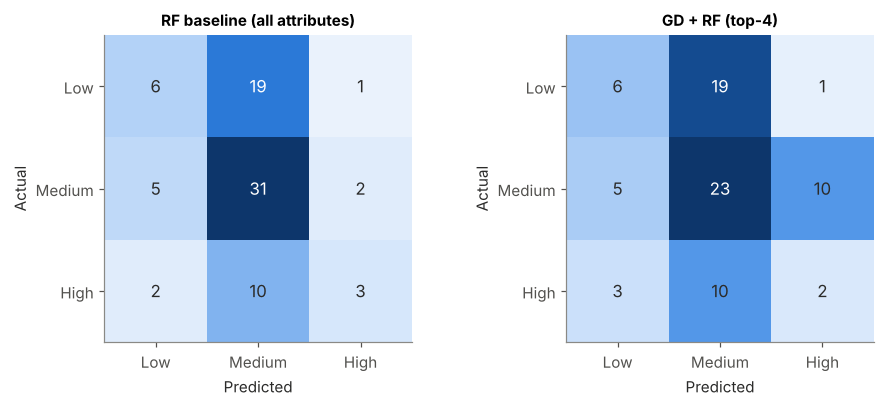

saved -> results/01_gd_confusion_matrices.png


In [32]:
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.8))
plot_confusion(axes[0], baseline["cm"], "RF baseline (all attributes)")
plot_confusion(axes[1], pipe["cm"], f"{SPEC['name']} + RF (top-{K})")
fig.tight_layout()
save_fig(fig, "01_gd_confusion_matrices")

### Two different notions of importance

* **Gate score (left):** learned by the gradient-trained surrogate; it decides *which attributes are selected*.
* **Random Forest MDI (right):** mean decrease in impurity from the trees *after* selection; it describes *how the forest uses* the attributes it was given (one-hot columns summed per attribute).

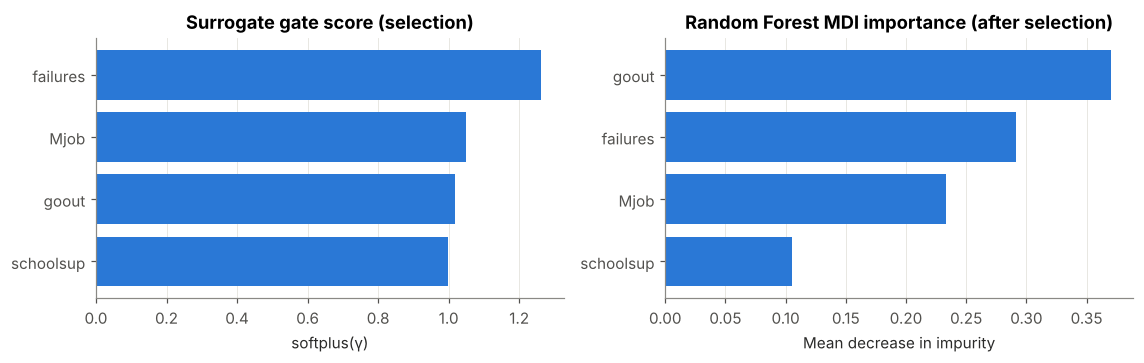

saved -> results/01_gd_feature_importance.png


In [33]:
# Random Forest's OWN importance (impurity / MDI) is a different quantity from the surrogate's gate score:
# gates measure usefulness for a LINEAR model; MDI measures how much the trees' splits reduce impurity.
rf_imp = rf_importance_by_attribute(pipe["model"], SEL_COLS, GIDX, ATTRS)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.4))
g_sel = gates[SELECTED]
axes[0].barh(g_sel.index[::-1], g_sel.to_numpy()[::-1], color=SPEC["color"])
axes[0].set_title("Surrogate gate score (selection)"); axes[0].set_xlabel("softplus(γ)")
axes[1].barh(rf_imp.index[::-1], rf_imp.to_numpy()[::-1], color=ACCENT)
axes[1].set_title("Random Forest MDI importance (after selection)"); axes[1].set_xlabel("Mean decrease in impurity")
for a in axes: a.grid(axis="y", visible=False)
fig.tight_layout()
save_fig(fig, "01_gd_feature_importance")

## 11. Variability: repeated cross-validation inside the training set

A single 79-student test set is noisy, so the **whole pipeline** (preprocessing → surrogate training with this optimizer → top-$K$ selection → Random Forest) is also evaluated with 5×3 repeated stratified CV on the training set. Feature selection is re-run inside every fold, so no fold ever sees its own validation rows.

In [34]:
# Variability: repeated stratified 5x3 CV of the whole pipeline INSIDE the training set
t0 = time.perf_counter()
cv_acc, cv_f1 = cv_pipeline(X_train, y_train, SPEC, BEST_LR, LAM, K)
cv_acc_b, cv_f1_b = cv_pipeline(X_train, y_train)
cv_table = pd.DataFrame({
    "CV accuracy (mean ± std)": [f"{cv_acc_b.mean():.3f} ± {cv_acc_b.std():.3f}", f"{cv_acc.mean():.3f} ± {cv_acc.std():.3f}"],
    "CV macro-F1 (mean ± std)": [f"{cv_f1_b.mean():.3f} ± {cv_f1_b.std():.3f}", f"{cv_f1.mean():.3f} ± {cv_f1.std():.3f}"]},
    index=["RF baseline (all attributes)", f"{SPEC['name']} + RF (top-{K})"])
display(cv_table)
print(f"15 folds | {time.perf_counter() - t0:.0f}s")

,CV accuracy (mean ± std),CV macro-F1 (mean ± std)
RF baseline (all attributes),0.512 ± 0.040,0.401 ± 0.059
GD + RF (top-4),0.486 ± 0.050,0.429 ± 0.058


15 folds | 9s


## 12. Save results

In [35]:
RESULT = {
    "optimizer": SPEC["name"], "learning_rate": BEST_LR,
    "batch_size": "full" if SPEC["batch"] is None else SPEC["batch"], "epochs": EPOCHS,
    "lambda_gate": LAM[0], "lambda_w": LAM[1], "feature_budget_k": K, "split_fingerprint": SPLIT_FINGERPRINT,
    "selected_features": SELECTED, "gates": gates.round(6).to_dict(),
    "test_metrics": pipe["metrics"], "acc_ci95": list(pipe["acc_ci"]), "f1_ci95": list(pipe["f1_ci"]),
    "confusion_matrix": pipe["cm"].tolist(),
    "baseline_test_metrics": baseline["metrics"],
    "feature_selection_time_s": fs_time, "rf_training_time_s": pipe["fit_time"], "lr_tuning_time_s": LR_TUNING_TIME,
    "final_objective": float(history[-1]), "reference_objective": REF_LOSS,
    "epochs_to_target": E2T, "loss_history": history.round(6).tolist(),
    "cv_accuracy_mean": float(cv_acc.mean()), "cv_accuracy_std": float(cv_acc.std()),
    "cv_f1_macro_mean": float(cv_f1.mean()), "cv_f1_macro_std": float(cv_f1.std()),
}
with open(os.path.join(RESULTS_DIR, "01_gd_results.json"), "w") as fh:
    json.dump(RESULT, fh, indent=2)
print(json.dumps({k: v for k, v in RESULT.items() if k not in ("gates", "loss_history")}, indent=2))

{
  "optimizer": "GD",
  "learning_rate": 0.3,
  "batch_size": "full",
  "epochs": 150,
  "lambda_gate": 0.2,
  "lambda_w": 0.3,
  "feature_budget_k": 4,
  "split_fingerprint": "dbafa1e6d7d9",
  "selected_features": [
    "failures",
    "Mjob",
    "goout",
    "schoolsup"
  ],
  "test_metrics": {
    "accuracy": 0.3924050632911392,
    "precision_macro": 0.3415750915750915,
    "recall_macro": 0.3231219073324336,
    "f1_macro": 0.317989417989418,
    "f1_weighted": 0.37170986538075146,
    "roc_auc_ovr_macro": 0.545575441758638
  },
  "acc_ci95": [
    0.2908227848101266,
    0.5063291139240507
  ],
  "f1_ci95": [
    0.21437266439756683,
    0.42889452585237314
  ],
  "confusion_matrix": [
    [
      6,
      19,
      1
    ],
    [
      5,
      23,
      10
    ],
    [
      3,
      10,
      2
    ]
  ],
  "baseline_test_metrics": {
    "accuracy": 0.5063291139240507,
    "precision_macro": 0.49273504273504276,
    "recall_macro": 0.41551956815114705,
    "f1_macro": 0.4086

## 13. Results and conclusion

**What Batch GD did.** With the tuned learning rate α = 0.3, Batch GD performed only **150 updates** (one per epoch). Its loss fell quickly for ~20 epochs and then crawled: after 150 epochs the objective is still **0.145 above the reference optimum**, so it never reached the convergence target (optimum + 0.02). The learned gates are therefore only weakly separated (1.26 for `failures` down to ≈0.9 for unused attributes), yet the ranking of the top four already matches the reference solution: **`failures`, `Mjob`, `goout`, `schoolsup`**.

**Random Forest results (test set, 79 students).** The GD-selected 4-attribute forest reached accuracy **0.392** and macro-F1 **0.318**, below the all-attribute baseline (accuracy 0.506, macro-F1 0.409). In the 5×3 repeated CV on the training set, however, the same pipeline scored macro-F1 **0.429 ± 0.058** versus **0.401 ± 0.059** for the baseline. The two estimates point in opposite directions and both differences are smaller than their uncertainty (bootstrap 95 % CI of test macro-F1: [0.214, 0.429] vs. [0.282, 0.523]), so the honest conclusion is that a 4-attribute subset performs *comparably* to using all 30 attributes – no reliable gain or loss.

**Conclusion.** Batch GD is the cheapest optimizer per epoch (≈0.06 s for all 150 updates) and perfectly smooth, but under an equal epoch budget it is by far the slowest to approach the optimum. Its feature ranking was nevertheless already correct, because the selection only needs the *order* of the gates, not their converged values. The comparison with the other optimizers is in Notebook 5.